In [1]:
import os

os.environ["OMP_NUM_THREADS"] = "4"
os.environ["OPENBLAS_NUM_THREADS"] = "4"
os.environ["MKL_NUM_THREADS"] = "4"
os.environ["VECLIB_MAXIMUM_THREADS"] = "4"
os.environ["NUMEXPR_NUM_THREADS"] = "4"

In [2]:
import matplotlib.pyplot as plt
from IPython.display import Image

import numpy as np
import scipy as sp

from scipy.optimize import minimize, minimize_scalar,shgo
from numpy.polynomial.polynomial import Polynomial
from numpy.polynomial.polynomial import polyroots, polyval, polytrim

from functools import partial

from scipy.special import factorial

import time

from tqdm import tqdm

from witness_anak import *
from witness_anam import *
from witness_num import *

# Linear Programming

For a short introduction to linear programming see  
https://en.wikipedia.org/wiki/Linear_programming


### Why the problem can be solved using linear programming

The optimization problem we consider has the form

\begin{equation}
f(\boldsymbol{\lambda}) =
\max\!\left(0,\max_{\mu \ge 0} \boldsymbol{\lambda}\cdot \mathbf{p}(\mu)\right)
-
\boldsymbol{\lambda}\cdot \mathbf{P},
\end{equation}

where $\mathbf{p}(\mu)$ is the vector of Poisson probabilities

\begin{equation}
p_k(\mu)=e^{-\mu}\frac{\mu^k}{k!}.
\end{equation}

Direct minimization of $f(\boldsymbol{\lambda})$ is difficult because the function is convex but generally **non-smooth**, due to the maximization over the continuous parameter $\mu$.

To obtain a numerically robust formulation, an auxiliary variable $t$ is introduced such that

\begin{equation}
t \ge \boldsymbol{\lambda}\cdot \mathbf{p}(\mu)
\qquad \forall \mu \ge 0.
\end{equation}

The optimization problem can then be written as

\begin{equation}
\min_{\boldsymbol{\lambda},t} \quad t - \boldsymbol{\lambda}\cdot \mathbf{P}
\end{equation}

subject to

\begin{equation}
t \ge \boldsymbol{\lambda}\cdot \mathbf{p}(\mu)
\quad \forall \mu \ge 0,
\end{equation}

\begin{equation}
t \ge 0,
\end{equation}

together with box constraints on the components of $\boldsymbol{\lambda}$.

The constraint $t \ge 0$ accounts for the limiting case $\mu \rightarrow \infty$, where $\boldsymbol{\lambda}\cdot\mathbf{p}(\mu) \rightarrow 0$.  
Therefore the clipping operation $\max(0,\cdot)$ in the original objective does not need to be handled explicitly in the algorithm.

For any **fixed value of $\mu$**, the constraint

\begin{equation}
t \ge \boldsymbol{\lambda}\cdot \mathbf{p}(\mu)
\end{equation}

is **linear in the variables $(\boldsymbol{\lambda},t)$**, and the objective function $t-\boldsymbol{\lambda}\cdot\mathbf{P}$ is also linear.  
The resulting optimization problem is therefore a **linear program**.

However, the family of constraints is indexed by the continuous parameter $\mu$.  
The problem is therefore a **linear program with infinitely many constraints**, known as a *semi-infinite linear program*.

In practice, the problem is solved using a **cutting-plane (exchange) method**.  
Starting from a small set of values $\mu_m$, a finite linear program is solved.  
The current solution is then checked by computing

\begin{equation}
\max_{\mu \ge 0} \boldsymbol{\lambda}\cdot \mathbf{p}(\mu).
\end{equation}

If this value exceeds the current value of $t$, the corresponding point $\mu^*$ is added to the set of constraints and the linear program is solved again.  
The procedure is repeated until no violated constraint is found.

### Cutting–plane solution of the semi-infinite LP

The reformulated optimization problem is a **linear program with infinitely many constraints**, because the inequality

\begin{equation}
t \ge \boldsymbol{\lambda}\cdot \mathbf{p}(\mu)
\end{equation}

must hold for all $\mu \ge 0$.  
Since it is impossible to include infinitely many constraints explicitly, the problem is solved iteratively using a **cutting-plane (exchange) method**.

The basic idea is to solve a sequence of finite linear programs while progressively adding only those constraints that are actually required.

---

### Algorithm outline

1. **Initialization**

   Start with a small set of parameter values

   \begin{equation}
   \mathcal{M}_0 = \{\mu_1,\mu_2,\dots\}.
   \end{equation}

   In practice a single value such as $\mu_1 = 0$ is sufficient.

---

2. **Solve the finite master LP**

   Solve the linear program

   \begin{equation}
   \min_{\boldsymbol{\lambda},t} \; t - \boldsymbol{\lambda}\cdot\mathbf{P}
   \end{equation}

   subject to

   \begin{equation}
   t \ge \boldsymbol{\lambda}\cdot\mathbf{p}(\mu_m)
   \qquad \forall \mu_m \in \mathcal{M},
   \end{equation}

   together with the constraint

   \begin{equation}
   t \ge 0.
   \end{equation}

   This produces a candidate solution $(\boldsymbol{\lambda},t)$.

---

3. **Search for the worst-case violation**

   For the current $\boldsymbol{\lambda}$ compute

   \begin{equation}
   w = \max_{\mu \ge 0} \boldsymbol{\lambda}\cdot\mathbf{p}(\mu).
   \end{equation}

   This step identifies the value $\mu^*$ that maximizes the inner expression.

---

4. **Check constraint violation**

   If

   \begin{equation}
   w - t \le \varepsilon
   \end{equation}

   for a chosen tolerance $\varepsilon$, then the current solution already satisfies all constraints and the algorithm terminates.

---

5. **Add a new constraint (cut)**

   If the inequality above is violated, the corresponding value $\mu^*$ defines a new constraint

   \begin{equation}
   t \ge \boldsymbol{\lambda}\cdot\mathbf{p}(\mu^*).
   \end{equation}

   The point $\mu^*$ is added to the set $\mathcal{M}$ and the linear program is solved again.

---

### Convergence

At each iteration a constraint that is violated by the current solution is added.  
Since the objective function is linear and the feasible region shrinks monotonically as constraints are added, the sequence of solutions converges to the optimum of the original semi-infinite linear program.

In practice only a **small number of cuts** is typically required before convergence is reached.

---

### Precomputed factorial array

Several routines require the array `fact`, which stores the inverse factorials

\begin{equation}
\texttt{fact}[i] = \frac{1}{i!}.
\end{equation}

This array is precomputed once and reused throughout the algorithm.  
It must contain entries up to the **largest index appearing in the vector `indx`**, which specifies which Poisson probabilities $p_k(\mu)$ are used in the nonclassicality witness.

Using a precomputed array avoids repeated evaluations of factorials inside tight loops and therefore significantly improves performance.

## Tests
### Jaynes-Cummings model

As a first test on a physical system let us assume Jaynes-Cummings model (JCM), for which all $P_n$ can be calculated analytically

\begin{equation}
\rho(\tau)=\sum_{n=0}^{\inf}\left|n\right\rangle\left\langle n \right| \frac{\overline{n}^n}{(1+\overline{n})^{1+n}}\left\lbrace p_e \left[\cos^2(\tau\sqrt{n+1}) +\frac{1+\overline{n}}{\overline{n}}\sin^2(\tau \sqrt{n})\right]+(1-p_e)\left[\cos^2(\tau\sqrt{n}) +\frac{\overline{n}}{1+\overline{n}}\sin^2(\tau \sqrt{n+1})\right]\right\rbrace,
\end{equation}

where $\tau=g t$ and $P_n = \left\langle n\right|\rho\left|n\right\rangle$. We will plot the results in the plane of $\tau$ and $\overline{n}$. The goal is to reproduce to reproduce or improve the results of [P. Marek et al., Phys. Rev. A 94, 013850 (2016)](https://doi.org/10.1103/PhysRevA.94.013850).

In [3]:
def Pjaycum(n,nu,tau,pe):
    nuf1 = nu**n/(1+nu)**(1+n)
    nuf2 = (1+nu)/nu
    nuf3 = nu/(1+nu)
    resA = (np.cos(tau*np.sqrt(n+1)))**2 + nuf2*(np.sin(tau*np.sqrt(n)))**2
    resB = (np.cos(tau*np.sqrt(n)))**2 + nuf3*(np.sin(tau*np.sqrt(n+1)))**2
    res = nuf1*(pe*resA + (1.0-pe)*resB)
    return res

In [4]:
tau = np.arange(0.01,10.001,0.02)
nu = np.arange(0.01,6.001,0.02)

N_tau = tau.shape[0]
N_nu = nu.shape[0]
N_P = 4

print("N_tau=",N_tau,"N_nu=",N_nu," N_P=",N_P,)

N_tau= 500 N_nu= 300  N_P= 4


In [5]:
xtau, ynu = np.meshgrid(tau, nu)

In [6]:
Paux=Pjaycum(n=1,nu=ynu,tau=xtau,pe=0.0)

In [7]:
Pall = np.empty((N_nu,N_tau,0))
for i1 in range(N_P):
    Paux = Pjaycum(n=i1,nu=ynu,tau=xtau,pe=1.0/3.0)
    Pall = np.append(Pall,Paux[...,np.newaxis],axis=2)

We will test the numerical LP solution against the a collection of analytical criteria that are easy to implement also fast. They include

\begin{align}
P_1 &> -P_0 \ln P_0
\end{align}

Klyshko criteria:
\begin{align}
(k+1)P_{k-1}P_{k+1} - k P^2_k &< 0,\;\text{for}\; k>1,\\
P_0 + \frac{P^2_1}{2P_2}\left[\exp\left(\frac{2P_2}{P_1}\right)-1\right]&>1
\end{align}

as well as their generalization

\begin{equation}
N P_N > P_{N-1} \ln{\left[
\sum_{k=0}^{N-1}\frac{N^k}{k!}\frac{P_N^k}{P^k_{N-1}} +
\frac{N^N}{N!}\frac{P^{N-1}_N}{P^N_{N-1}}\left(1-\sum_{k=0}^{N-2}P_k\right) 
\right]}
\end{equation}


In [8]:
def extract_binary_boundary(P0_all, P1_all, nonclass_num):
    """
    Returns ordered boundary curves between 0 and 1 regions.

    Output:
        boundaries = [array([[P0, P1], ...]), ...]
    """
    fig, ax = plt.subplots()

    cs = ax.contour(P0_all, P1_all, nonclass_num, levels=[0.5])

    boundaries = []
    for path in cs.get_paths():
        v = path.vertices
        if len(v) > 1:
            boundaries.append(v.copy())

    plt.close(fig)
    return boundaries

## 4 P criteria

In [9]:
def run2D(N0=512,N1=512,indx=np.array([0,1,2,3],dtype=np.int16),dPA=0.0,uPA=1.0,dPB=0.0,uPB=0.4,Prest=np.array([0.05,0.05]),fi="aux.npy"):
    N_P=len(indx)

    PA_all = np.linspace(dPA, uPA, num=N0, endpoint=True)
    PB_all = np.linspace(dPB, uPB, num=N1, endpoint=True)


    Pall = np.empty((N1, N0, N_P))

    
    Pall[..., 0] = PA_all[None, :]
    Pall[..., 1] = PB_all[:, None]
    Pall[..., 2:] = Prest[None, None, :]
    

    fact = np.array([1.0/factorial(i1) for i1 in range(np.max(indx)+1)])

    nonclass_num = np.zeros((N1,N0), dtype=np.int8)
    nonclass_c = np.zeros((N1,N0))
    all_lambda = np.zeros((*nonclass_num.shape,N_P))
    tol=1e-10
    bias=1e-8

    bounds = [(-1.0, 1.0)] * N_P


    mu_star = 0.0

    for i0 in tqdm(range(N0)):
        lam_aux=np.zeros(N_P)
        for i1 in range(N1):
            Pin = Pall[i1,i0,:]

            w, mu_star = max_inner_value(indx, lam_aux, fact)
            true_obj = lam_aux @ Pin - w
            #true_obj = 0
            if(true_obj > bias):
                nonclass_num[i1,i0] = 1
                nonclass_c[i1,i0]=true_obj
                all_lambda[i1,i0,:]= lam_aux

            else:
                result = solve_semi_infinite_lp(Pin, indx, fact, bounds,
                                   mu_init=(0,),
                                   tol=tol, max_iter=300, imtol=1e-8,lp_failed_continue=True)
 
                w, mu_star = max_inner_value(indx, result["lam"], fact)
                true_obj = result["lam"] @ Pin - w
        
                if(true_obj > bias):
                    nonclass_num[i1,i0] = 1
                    lam_aux = result["lam"]
                
                nonclass_c[i1,i0]=true_obj
                all_lambda[i1,i0,:]= result["lam"]


    boundaries = extract_binary_boundary(PA_all, PB_all, nonclass_num)


    ###Analytical 

    nonclass_anaK, ncaf_anaK = analytical_k(Pall, fact, indx=indx)
    boundaries_anaK = extract_binary_boundary(PA_all, PB_all, nonclass_anaK)

    ###Gen Klyshko

    nonclass_anaM, ncaf_anaM, nagM = analytical_m(Pall,indx=indx)
    print("Number=",nagM)
    boundaries_anaM = extract_binary_boundary(PA_all, PB_all, nonclass_anaM)

    nonclass_ana = np.where(nonclass_anaK + nonclass_anaM > 0.5,1,0)
    boundaries_ana = extract_binary_boundary(PA_all, PB_all, nonclass_ana)
    
    with open(fi, 'wb') as f:
        np.save(f,PA_all)
        np.save(f,PB_all)
        np.save(f,Prest)
        np.save(f, np.array(boundaries, dtype=object), allow_pickle=True)
        np.save(f, np.array(boundaries_ana, dtype=object), allow_pickle=True)
        np.save(f, np.array(boundaries_anaK, dtype=object), allow_pickle=True)
        np.save(f, np.array(boundaries_anaM, dtype=object), allow_pickle=True)
        np.save(f,nonclass_num)
        np.save(f,nonclass_ana)
        return boundaries, boundaries_ana, boundaries_anaK, boundaries_anaM

In [14]:
N0=100
N1=200
idx=np.array([0,2,4,6],dtype=np.int16)
dPA=1e-10
uPA=0.9
dPB=1e-10
uPB=0.3
Prest=np.array([0.05,0.05])

fi='../test.npy'

boundaries, boundaries_ana, boundaries_ana1, boundaries_anaM  = run2D(N0=N0,N1=N1,indx=idx,dPA=dPA,uPA=uPA,dPB=dPB,uPB=uPB,Prest=Prest,fi=fi)

100%|██████████| 100/100 [00:14<00:00,  6.92it/s]


(array([4, 0], dtype=int16), array([2, 2], dtype=int16))
(array([6, 0], dtype=int16), array([4, 2], dtype=int16))
(array([6, 2], dtype=int16), array([4, 4], dtype=int16))
(array([6, 0, 0], dtype=int16), array([2, 2, 2], dtype=int16))
(array([6, 6, 0], dtype=int16), array([4, 4, 4], dtype=int16))
(array([6, 4, 0, 0, 0], dtype=int16), array([2, 2, 2, 2, 2], dtype=int16))
(array([6, 6, 0, 0, 0], dtype=int16), array([4, 2, 2, 2, 2], dtype=int16))
(array([6, 6, 6, 0, 0], dtype=int16), array([4, 4, 4, 4, 2], dtype=int16))
(array([6, 6, 6, 2, 0], dtype=int16), array([4, 4, 4, 4, 4], dtype=int16))
(array([6, 4, 4, 0, 0, 0, 0], dtype=int16), array([2, 2, 2, 2, 2, 2, 2], dtype=int16))
(array([6, 6, 6, 0, 0, 0, 0], dtype=int16), array([4, 4, 2, 2, 2, 2, 2], dtype=int16))
(array([6, 6, 4, 0, 0, 0, 0, 0], dtype=int16), array([2, 2, 2, 2, 2, 2, 2, 2], dtype=int16))
(array([6, 6, 6, 0, 0, 0, 0, 0], dtype=int16), array([4, 2, 2, 2, 2, 2, 2, 2], dtype=int16))
(array([6, 4, 4, 4, 0, 0, 0, 0, 0], dtype=i

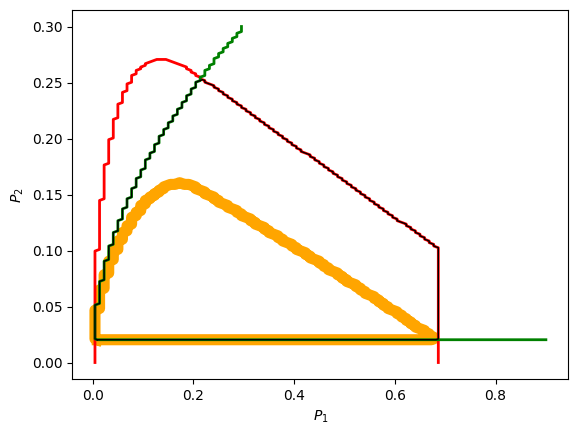

In [15]:
fig, ax = plt.subplots()

for b in boundaries:
    ax.plot(b[:, 0], b[:, 1], lw=8,color="orange")

for b in boundaries_ana1:
    ax.plot(b[:, 0], b[:, 1], lw=2, color="red")

for b in boundaries_anaM:
    ax.plot(b[:, 0], b[:, 1], lw=2, color="green")

for b in boundaries_ana:
    ax.plot(b[:, 0], b[:, 1], lw=1, color="black")

ax.set_xlabel(r"$P_1$")
ax.set_ylabel(r"$P_2$")
plt.show()

In [ ]:
print(boundaries)
print(boundaries_ana1)